# Command의 갱신과 이동

**이 노트북에서 할 일**

1. 점수 칸을 읽어 갱신과 다음 노드 이름을 함께 담는 노드를 만듭니다.
2. 그 노드를 그래프 없이 먼저 불러 담긴 두 가지를 봅니다.
3. 그 노드를 붙인 그래프에 점수 하나만 바꿔 두 번 실행합니다.
4. 목적지를 적지 않은 판과 03절 조건부 엣지 판을 차례로 견줍니다.

**준비물** — 이 절은 OpenAI API 키를 쓰지 않습니다.
모델 요청이 0번이라 드는 비용이 없습니다.
읽어 오는 자료 파일도 없고 새로 쓰는 파일도 없습니다.
실행 시간은 1분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangGraph 1.2.11과 도구 파일이 쓰는 numpy 2.5.3을 설치합니다.
메시지 클래스를 쓰지 않아 04절에서 설치한 LangChain은 설치하지 않습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
노드 하나가 갱신과 다음 노드 이름을 함께 내놓게 만들어 붙이는 자리입니다.
8절과 9절은 판을 하나씩 바꿔 보는 자리입니다.
10절은 네 실행을 기록 한 줄씩으로 만들어 표로 견주는 자리입니다.
준비부터 끝까지 함께 실행하고 실습 시간에 다시 읽습니다.

실습 폴더 `labs/part4/ch13-langgraph-basics`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

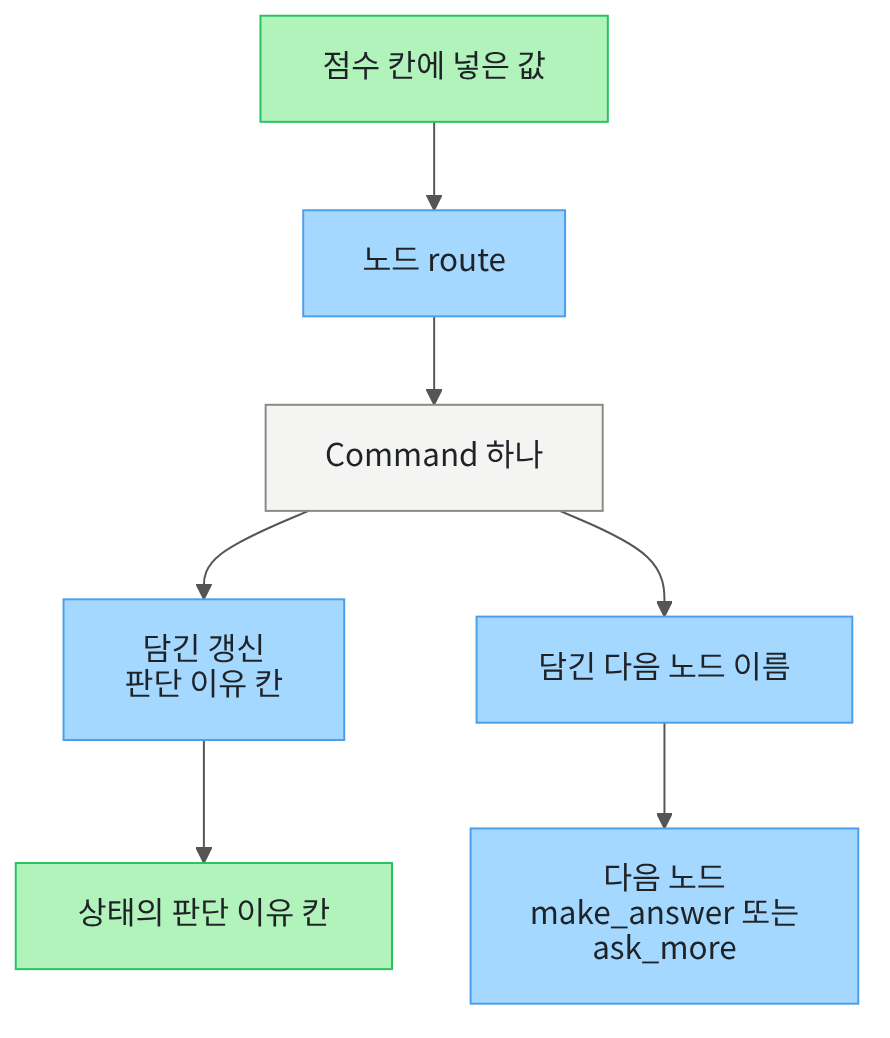

맨 위 초록 상자가 그래프에 넣은 점수 칸입니다.
그 아래 파란 상자가 점수 칸을 읽는 우리 노드입니다.
가운데 회색 상자가 라이브러리가 주는 `Command` 하나입니다.
거기서 갈라진 왼쪽 줄기가 상태에 넣을 갱신입니다.
오른쪽 줄기가 이어서 지날 노드 이름입니다.

## 1. 준비

첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "numpy==2.5.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 `langgraph: 1.2.11`과 `numpy: 2.5.3`이 보입니다.
패키지 `numpy`는 이 절이 직접 쓰지 않지만 도구 파일을 불러올 때 필요합니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이름 여섯 개를 불러옵니다.
앞의 다섯은 02절에서 불러온 것과 같습니다.
마지막 하나가 이 절에서 처음 쓰는 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 02절 노드 `normalize`와 03절 길 끝 노드 `make_answer`·`ask_more`를 가져옵니다.

In [2]:
# 02절 이름 다섯 개에 이 절 이름 하나를 더해 불러옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
# 02절 노드 normalize와 03절 길 끝 노드 둘을 도구 파일에서 가져옵니다
from rag_tools import ask_more, make_answer, normalize

print("이 절에서 처음 쓰는 이름:", "Command")

이 절에서 처음 쓰는 이름: Command


**결과 읽기** — 출력 줄 `이 절에서 처음 쓰는 이름: Command`가 보입니다.
객체 `Command`는 상태에 넣을 갱신과 다음에 지날 노드 이름을 함께 담습니다.
05절에서 쓴 `Send`와 같은 자리에서 가져옵니다.
도구 파일에서 가져온 노드 셋은 출력하지 않습니다.

## 2. 이 절에서 쓸 값 정하기

01절부터 쓴 첫 질문을 글자까지 같게 씁니다.
길을 가를 점수 두 개와 기준값도 03절 값을 그대로 씁니다.
같은 값을 써야 03절 결과와 이 절 결과를 나란히 볼 수 있습니다.

In [3]:
# 01절 질문과 03절에서 쓴 점수 두 개와 기준값을 그대로 씁니다
first_question = "  대출 기간은 며칠인가요?  "
high_score = 0.82
low_score = 0.41
enough_score = 0.7
print("첫 질문:", first_question)
print("첫 질문의 글자 수:", len(first_question))
print("높은 점수:", high_score)
print("낮은 점수:", low_score)
print("길을 가르는 기준값:", enough_score)

첫 질문:   대출 기간은 며칠인가요?  
첫 질문의 글자 수: 17
높은 점수: 0.82
낮은 점수: 0.41
길을 가르는 기준값: 0.7


**결과 읽기** — 출력 줄 `첫 질문의 글자 수: 17`은 01절부터 이어지는 같은 값입니다.
출력 줄 `높은 점수: 0.82`와 `낮은 점수: 0.41`이 길을 가를 두 값입니다.
출력 줄 `길을 가르는 기준값: 0.7`이 그 둘을 가르는 값입니다.
점수가 기준값과 같거나 크면 자료가 넉넉하다고 봅니다.

## 3. 상태 형식과 출력 함수

이 절 상태에는 판단 이유를 적을 칸이 하나 더 필요합니다.
대신 03절에서 쓴 검색어 칸은 이 절에서 쓰지 않아 뺍니다.
칸 구성이 03절과 달라 형식 이름도 새로 붙입니다.

In [4]:
# 03절 상태 형식에서 검색어 칸을 빼고 판단 이유 칸을 더한 상태 형식을 만듭니다
class DecisionState(TypedDict):
    question: str
    score: float
    decision: str
    answer: str
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `decision`이 이 절에서 새로 더한 판단 이유 칸입니다.
실행 흔적 칸에는 02절에서 쓴 같은 규칙을 적었습니다.
나머지 세 칸에는 규칙을 적지 않아 덮어쓰기가 됩니다.

다음 셀은 01절부터 쓴 출력 함수를 이 절 칸에 맞춘 판입니다.

In [5]:
# 상태의 칸 다섯 개를 라벨 줄 아래에 한 줄씩 출력합니다
def print_state(label, state):
    print(label)
    print("질문 칸 |", state["question"])
    print("점수 칸 |", state["score"])
    print("판단 이유 칸 |", state["decision"])
    print("답 칸 |", state["answer"])
    print("실행 흔적 칸 |", state["trace"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
03절 판과 견주면 검색어 칸 줄이 빠지고 판단 이유 칸 줄이 들어왔습니다.
다섯 칸 모두 한 줄로 나오는 값이라 개수만 적지 않고 값을 그대로 출력합니다.

다음 셀은 점수만 바꿔 처음 상태를 만드는 함수입니다.
03절에서 쓴 함수에 판단 이유 칸 한 줄을 더했습니다.

In [6]:
# 점수 칸만 다른 처음 상태를 만들어 냅니다
def new_state(score):
    state = {}
    state["question"] = first_question
    state["score"] = score
    state["decision"] = ""
    state["answer"] = ""
    state["trace"] = []
    return state

**결과 읽기** — 정의 셀이라 출력이 없습니다.
판단 이유 칸과 답 칸은 빈 글로 두고 실행이 채우게 합니다.
실행 흔적 칸은 빈 목록으로 두고 노드마다 이름 하나씩 이어 붙입니다.

## 4. 길 끝에서 답을 적는 노드 셋

노드 셋은 준비 셀에서 도구 파일로부터 가져왔습니다.
노드 `normalize`는 02절 판이고 질문 칸의 앞뒤 빈칸만 없앱니다.
길 끝 노드 `make_answer`와 `ask_more`는 03절에서 만든 노드입니다.
앞 노드는 자료가 넉넉할 때, 뒤 노드는 모자랄 때 지나는 길 끝입니다.
세 노드 모두 자기 칸과 자기 이름만 담아 내고 점수 칸과 판단 이유 칸은 건드리지 않습니다.

## 5. 갱신과 이동을 함께 내놓는 노드

03절에서는 조건 함수가 이름표만 내놓고 칸은 고치지 못했습니다.
그래서 어떤 까닭으로 그 길을 골랐는지 상태에 남지 않았습니다.
이 절 노드는 객체 `Command` 하나에 갱신과 다음 노드 이름을 함께 담습니다.
자리 `update`에는 일반 노드가 내놓는 것과 같은 딕셔너리를 적습니다.
자리 `goto`에는 이어서 지날 노드 이름을 적습니다.

In [7]:
# 점수 칸을 읽어 판단 이유 칸 갱신과 다음 노드 이름을 함께 담아 냅니다
def route(state):
    if state["score"] >= enough_score:
        return Command(update={"decision": "자료가 넉넉함", "trace": ["route"]}, goto="make_answer")
    return Command(update={"decision": "자료가 모자람", "trace": ["route"]}, goto="ask_more")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
점수가 기준값과 같거나 크면 자료가 넉넉하다고 적고 답 만들기 쪽으로 보냅니다.
그렇지 않으면 자료가 모자라다고 적고 자료 더 찾기 쪽으로 보냅니다.
실행 흔적 칸에는 이 노드도 자기 이름 하나만 담습니다.

다음 셀은 그래프 없이 이 노드만 두 점수로 불러 봅니다.

In [8]:
# 그래프 없이 이 노드만 두 점수로 불러 담긴 두 가지를 봅니다
high_command = route({"score": high_score})
low_command = route({"score": low_score})
print("높은 점수로 낸 것의 종류:", type(high_command))
print("높은 점수로 낸 갱신:", high_command.update)
print("높은 점수로 정한 다음 노드:", high_command.goto)
print("낮은 점수로 낸 갱신:", low_command.update)
print("낮은 점수로 정한 다음 노드:", low_command.goto)

높은 점수로 낸 것의 종류: <class 'langgraph.types.Command'>
높은 점수로 낸 갱신: {'decision': '자료가 넉넉함', 'trace': ['route']}
높은 점수로 정한 다음 노드: make_answer
낮은 점수로 낸 갱신: {'decision': '자료가 모자람', 'trace': ['route']}
낮은 점수로 정한 다음 노드: ask_more


**결과 읽기** — 출력 줄 `높은 점수로 낸 갱신: {'decision': '자료가 넉넉함', 'trace': ['route']}`이 담긴 갱신입니다.
출력 줄 `높은 점수로 정한 다음 노드: make_answer`가 담긴 노드 이름입니다.
낮은 점수에서는 갱신과 노드 이름이 모두 달라졌습니다.
출력 줄 `낮은 점수로 정한 다음 노드: ask_more`가 그 자리입니다.
갱신 쪽 모양은 01절부터 본 노드 갱신과 같습니다.

## 6. 조립과 실행

설계 객체를 만들고 노드 넷을 등록합니다.
노드 `route`를 등록할 때 갈 수 있는 목적지를 함께 적습니다.
인자 `destinations`는 실행이 아니라 구조 그림에만 쓰입니다.
8절에서 이 인자를 빼고 무엇이 달라지는지 봅니다.

In [9]:
# 설계 객체를 만들고 노드 네 개를 등록하면서 route의 목적지를 함께 적습니다
builder = StateGraph(DecisionState)
builder.add_node("normalize", normalize)
builder.add_node("route", route, destinations=("make_answer", "ask_more"))
builder.add_node("make_answer", make_answer)
builder.add_node("ask_more", ask_more)
print("등록한 노드 수:", len(builder.nodes))

등록한 노드 수: 4


**결과 읽기** — 출력 줄 `등록한 노드 수: 4`가 보입니다.
01절·02절은 둘, 03절은 넷, 04절은 셋, 05절은 둘이었습니다.

다음 셀은 고정 엣지만 적고 컴파일합니다.
03절은 갈래를 조건부 엣지로 적었지만 이 절은 적지 않습니다.
갈래를 정하는 일을 노드가 맡았기 때문입니다.

In [10]:
# 고정 엣지 네 개만 적고 컴파일합니다
builder.add_edge(START, "normalize")
builder.add_edge("normalize", "route")
builder.add_edge("make_answer", END)
builder.add_edge("ask_more", END)
graph = builder.compile()
print("고정 엣지로 적은 수:", len(builder.edges))
print("컴파일 결과의 종류:", type(graph))

고정 엣지로 적은 수: 4
컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 4`가 보입니다.
03절은 고정 엣지 넷에 조건부 엣지 하나를 더 적었습니다.
출력 줄의 종류 이름 `CompiledStateGraph`는 01절부터 같습니다.

다음 셀은 그래프가 스스로 그린 구조 문자열을 봅니다.
줄이 많아 노드 이름이 든 줄만 골라 출력합니다.

In [11]:
# 그래프가 스스로 그린 구조 문자열에서 route가 나오는 줄만 골라 출력합니다
structure_text = graph.get_graph().draw_mermaid()
print("구조 문자열에서 route가 나오는 줄")
for line in structure_text.split("\n"):
    if "route" in line:
        print(line.strip())

구조 문자열에서 route가 나오는 줄
route(route)
normalize --> route;
route -.-> ask_more;
route -.-> make_answer;


**결과 읽기** — 라벨 줄 `구조 문자열에서 route가 나오는 줄` 아래 네 줄이 나옵니다.
줄 `normalize --> route;`는 우리가 적은 고정 엣지입니다.
줄 `route -.-> ask_more;`와 `route -.-> make_answer;`는 점선으로 그려집니다.
등록할 때 적어 둔 목적지 둘이 이 두 줄이 됐습니다.

다음 셀은 점수 칸에 높은 점수를 넣고 실행합니다.
실행 전에 예상해 봅니다.
점수가 기준값보다 크니 답 만들기 쪽으로 갈 것입니다.

In [12]:
# 점수 칸에 높은 점수를 넣고 그래프를 실행합니다
high_state = new_state(high_score)
high_result = graph.invoke(high_state)
print_state("높은 점수 결과", high_result)
assert high_result["trace"] == ["normalize", "route", "make_answer"]

높은 점수 결과
질문 칸 | 대출 기간은 며칠인가요?
점수 칸 | 0.82
판단 이유 칸 | 자료가 넉넉함
답 칸 | 찾은 자료로 답을 만듭니다
실행 흔적 칸 | ['normalize', 'route', 'make_answer']


**결과 읽기** — 줄 `판단 이유 칸 | 자료가 넉넉함`이 노드가 남긴 판단입니다.
줄 `답 칸 | 찾은 자료로 답을 만듭니다`가 길 끝 노드가 적은 답입니다.
줄 `실행 흔적 칸 | ['normalize', 'route', 'make_answer']`에 이름이 셋 남았습니다.
판단을 적은 자리와 길을 고른 자리가 같은 노드입니다.

## 7. 점수 하나만 바꿔 다시 실행

바꿀 값은 점수 하나입니다.
그래프도 노드도 그대로 두고 낮은 점수를 넣습니다.
실행 전에 예상해 봅니다.
점수가 기준값보다 작으니 자료 더 찾기 쪽으로 갈 것입니다.

In [13]:
# 점수 칸에 낮은 점수를 넣고 같은 그래프를 실행합니다
low_state = new_state(low_score)
low_result = graph.invoke(low_state)
print_state("낮은 점수 결과", low_result)
assert low_result["trace"] == ["normalize", "route", "ask_more"]

낮은 점수 결과
질문 칸 | 대출 기간은 며칠인가요?
점수 칸 | 0.41
판단 이유 칸 | 자료가 모자람
답 칸 | 자료를 더 찾아야 합니다
실행 흔적 칸 | ['normalize', 'route', 'ask_more']


**결과 읽기** — 줄 `판단 이유 칸 | 자료가 모자람`으로 판단이 바뀌었습니다.
줄 `답 칸 | 자료를 더 찾아야 합니다`로 답도 바뀌었습니다.
줄 `실행 흔적 칸 | ['normalize', 'route', 'ask_more']`에서 마지막 이름만 달라졌습니다.
점수 하나만 바꿨는데 판단과 길이 함께 달라졌습니다.

다음 셀은 두 실행을 칸별로 견줍니다.

In [14]:
# 두 실행의 결과를 칸별로 견줍니다
print("판단 이유 칸이 같은가:", high_result["decision"] == low_result["decision"])
print("답 칸이 같은가:", high_result["answer"] == low_result["answer"])
print("실행 흔적 칸이 같은가:", high_result["trace"] == low_result["trace"])
print("지난 노드 수가 같은가:", len(high_result["trace"]) == len(low_result["trace"]))

판단 이유 칸이 같은가: False
답 칸이 같은가: False
실행 흔적 칸이 같은가: False
지난 노드 수가 같은가: True


**결과 읽기** — 출력 줄 `판단 이유 칸이 같은가: False`와 `답 칸이 같은가: False`가 갈린 자리입니다.
출력 줄 `실행 흔적 칸이 같은가: False`도 마지막 이름에서 갈렸습니다.
출력 줄 `지난 노드 수가 같은가: True`는 두 실행이 셋으로 같았습니다.
길은 갈렸지만 지나간 노드 수는 같습니다.

## 8. 값 바꿔 보기 ① 목적지를 적지 않으면

바꿀 값은 등록할 때 적은 목적지 하나입니다.
같은 노드와 같은 엣지로 판을 하나 더 만들되 그 인자만 뺍니다.
실행 전에 예상해 봅니다.
객체 `Command`가 실행 때 목적지를 정하므로 결과는 같을 것입니다.

In [15]:
# 같은 노드와 같은 엣지로 목적지만 적지 않은 판을 하나 더 만듭니다
plain_builder = StateGraph(DecisionState)
plain_builder.add_node("normalize", normalize)
plain_builder.add_node("route", route)
plain_builder.add_node("make_answer", make_answer)
plain_builder.add_node("ask_more", ask_more)
plain_builder.add_edge(START, "normalize")
plain_builder.add_edge("normalize", "route")
plain_builder.add_edge("make_answer", END)
plain_builder.add_edge("ask_more", END)
plain_graph = plain_builder.compile()
print("목적지를 적지 않은 판의 노드 수:", len(plain_builder.nodes))

목적지를 적지 않은 판의 노드 수: 4


**결과 읽기** — 출력 줄 `목적지를 적지 않은 판의 노드 수: 4`가 앞 그래프와 같습니다.
노드도 엣지도 앞 그래프와 같은 것을 씁니다.
다른 것은 등록할 때 적은 목적지 하나뿐입니다.

다음 셀은 이 판의 구조 문자열을 같은 방법으로 봅니다.

In [16]:
# 목적지를 적지 않은 판의 구조 문자열에서도 route가 나오는 줄만 봅니다
plain_text = plain_graph.get_graph().draw_mermaid()
print("목적지를 적지 않은 판에서 route가 나오는 줄")
for line in plain_text.split("\n"):
    if "route" in line:
        print(line.strip())

목적지를 적지 않은 판에서 route가 나오는 줄
route(route)
normalize --> route;
route --> __end__;


**결과 읽기** — 라벨 줄 아래 세 줄만 나옵니다.
줄 `route --> __end__;`가 목적지 두 줄 대신 들어왔습니다.
갈 수 있는 곳을 적어 두지 않아 구조 그림이 실제 이동과 다릅니다.
구조 그림을 남에게 보일 때는 목적지를 적어 두는 편이 낫습니다.

다음 셀은 이 판에 같은 낮은 점수를 넣어 실행합니다.

In [17]:
# 목적지를 적지 않은 판에 낮은 점수를 넣어 실행합니다
plain_result = plain_graph.invoke(new_state(low_score))
print_state("목적지를 적지 않은 판 · 낮은 점수", plain_result)
print("목적지를 적어 둔 판의 결과와 같은가:", plain_result == low_result)

목적지를 적지 않은 판 · 낮은 점수
질문 칸 | 대출 기간은 며칠인가요?
점수 칸 | 0.41
판단 이유 칸 | 자료가 모자람
답 칸 | 자료를 더 찾아야 합니다
실행 흔적 칸 | ['normalize', 'route', 'ask_more']
목적지를 적어 둔 판의 결과와 같은가: True


**결과 읽기** — 줄 `판단 이유 칸 | 자료가 모자람`으로 앞 실행과 같습니다.
줄 `실행 흔적 칸 | ['normalize', 'route', 'ask_more']`도 같습니다.
출력 줄 `목적지를 적어 둔 판의 결과와 같은가: True`가 그 사실을 한 줄로 보여 줍니다.
적어 둔 목적지는 구조 그림에만 쓰이고 실행은 바꾸지 않았습니다.

## 9. 값 바꿔 보기 ② 03절 조건부 엣지 판과 견주기

바꿀 것은 길을 고르는 자리 하나입니다.
같은 점수와 같은 길 끝 노드를 쓰되 03절 모양으로 판을 하나 더 만듭니다.
실행 전에 예상해 봅니다.
조건 함수는 칸을 고치지 못하니 판단 이유 칸이 빈 글로 남을 것입니다.

In [18]:
# 점수 칸을 기준값과 견줘 이름표 하나를 내놓는 03절 조건 함수를 적습니다
def choose_path(state):
    if state["score"] >= enough_score:
        return "enough"
    return "short"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수는 03절에서 만든 조건 함수입니다.
노트북에서 정한 기준값을 읽으므로 도구 파일에 두지 않고 여기 적었습니다.
이름표 `enough`와 `short` 가운데 하나를 내놓습니다.
칸을 고치는 자리가 없다는 점이 이 절 노드와 다릅니다.

다음 셀은 이 조건 함수로 03절 모양 판을 만듭니다.

In [19]:
# route 노드 없이 03절 모양으로 조건부 엣지 판을 만듭니다
edge_builder = StateGraph(DecisionState)
edge_builder.add_node("normalize", normalize)
edge_builder.add_node("make_answer", make_answer)
edge_builder.add_node("ask_more", ask_more)
path_map = {"enough": "make_answer", "short": "ask_more"}
edge_builder.add_edge(START, "normalize")
edge_builder.add_conditional_edges("normalize", choose_path, path_map)
edge_builder.add_edge("make_answer", END)
edge_builder.add_edge("ask_more", END)
edge_graph = edge_builder.compile()
print("조건부 엣지 판의 노드 수:", len(edge_builder.nodes))
print("조건부 엣지 판의 고정 엣지 수:", len(edge_builder.edges))

조건부 엣지 판의 노드 수: 3
조건부 엣지 판의 고정 엣지 수: 3


**결과 읽기** — 출력 줄 `조건부 엣지 판의 노드 수: 3`으로 노드가 하나 적습니다.
길을 고르는 일을 노드가 아니라 조건 함수가 맡기 때문입니다.
출력 줄 `조건부 엣지 판의 고정 엣지 수: 3`이고 조건부 엣지는 이 수에 들어가지 않습니다.

다음 셀은 이 판에 같은 낮은 점수를 넣어 실행합니다.

In [20]:
# 조건부 엣지 판에 같은 낮은 점수를 넣어 실행합니다
edge_result = edge_graph.invoke(new_state(low_score))
print_state("조건부 엣지 판 · 낮은 점수", edge_result)

조건부 엣지 판 · 낮은 점수
질문 칸 | 대출 기간은 며칠인가요?
점수 칸 | 0.41
판단 이유 칸 | 
답 칸 | 자료를 더 찾아야 합니다
실행 흔적 칸 | ['normalize', 'ask_more']


**결과 읽기** — 줄 `답 칸 | 자료를 더 찾아야 합니다`로 답은 앞 판과 같습니다.
줄 `판단 이유 칸 |` 뒤에는 아무 글도 없습니다.
줄 `실행 흔적 칸 | ['normalize', 'ask_more']`에 이름이 둘뿐입니다.
같은 길로 갔지만 고른 까닭이 상태에 남지 않았습니다.

다음 셀은 두 판을 나란히 견줍니다.

In [21]:
# 두 판의 답 칸과 판단 이유 칸과 지난 노드 수를 견줍니다
print("두 판의 답 칸이 같은가:", edge_result["answer"] == low_result["answer"])
print("Command 판의 판단 이유 칸:", low_result["decision"])
print("조건부 엣지 판의 판단 이유 칸이 빈 글인가:", edge_result["decision"] == "")
print("Command 판의 지난 노드 수:", len(low_result["trace"]))
print("조건부 엣지 판의 지난 노드 수:", len(edge_result["trace"]))

두 판의 답 칸이 같은가: True
Command 판의 판단 이유 칸: 자료가 모자람
조건부 엣지 판의 판단 이유 칸이 빈 글인가: True
Command 판의 지난 노드 수: 3
조건부 엣지 판의 지난 노드 수: 2


**결과 읽기** — 출력 줄 `두 판의 답 칸이 같은가: True`로 닿은 곳은 같습니다.
출력 줄 `Command 판의 판단 이유 칸: 자료가 모자람`과 `조건부 엣지 판의 판단 이유 칸이 빈 글인가: True`가 갈린 자리입니다.
출력 줄 `Command 판의 지난 노드 수: 3`과 `조건부 엣지 판의 지난 노드 수: 2`도 함께 갈렸습니다.
갱신과 이동을 한 노드가 맡으면 노드가 하나 늘고 고른 까닭이 남습니다.

## 10. 네 실행을 기록 한 줄씩으로

끝까지 지난 실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~12와 01~05절에서 쓴 기록 한 줄과 같은 모양입니다.

In [22]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, state):
    row = {"실행": run_name}
    row["점수 칸"] = state["score"]
    row["판단 이유 칸"] = state["decision"]
    row["지난 노드 수"] = len(state["trace"])
    row["답 칸"] = state["answer"]
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
03절 판과 견주면 담는 칸에 판단 이유 칸과 지난 노드 수가 들어왔습니다.
이 절이 견주는 값이 그 둘이기 때문입니다.

다음 셀은 네 실행의 기록을 한 목록에 담습니다.

In [23]:
# 네 실행의 기록을 한 목록에 담습니다
run_rows = []
run_rows.append(run_row("Command 판 · 높은 점수", high_result))
run_rows.append(run_row("Command 판 · 낮은 점수", low_result))
run_rows.append(run_row("목적지를 적지 않은 판 · 낮은 점수", plain_result))
run_rows.append(run_row("조건부 엣지 판 · 낮은 점수", edge_result))
print("담은 기록 줄 수:", len(run_rows))

담은 기록 줄 수: 4


**결과 읽기** — 출력 줄 `담은 기록 줄 수: 4`가 보입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [24]:
# 실행과 점수 칸과 판단 이유 칸과 지난 노드 수와 답 칸을 라벨 줄 아래에 출력합니다
print("실행 | 점수 칸 | 판단 이유 칸 | 지난 노드 수 | 답 칸")
for row in run_rows:
    print(row["실행"], "|", row["점수 칸"], "|", row["판단 이유 칸"], "|", row["지난 노드 수"], "|", row["답 칸"])

실행 | 점수 칸 | 판단 이유 칸 | 지난 노드 수 | 답 칸
Command 판 · 높은 점수 | 0.82 | 자료가 넉넉함 | 3 | 찾은 자료로 답을 만듭니다
Command 판 · 낮은 점수 | 0.41 | 자료가 모자람 | 3 | 자료를 더 찾아야 합니다
목적지를 적지 않은 판 · 낮은 점수 | 0.41 | 자료가 모자람 | 3 | 자료를 더 찾아야 합니다
조건부 엣지 판 · 낮은 점수 | 0.41 |  | 2 | 자료를 더 찾아야 합니다


**결과 읽기** — 라벨 줄 아래 네 줄이 나옵니다.
첫 줄과 둘째 줄은 점수만 다르고 판단 이유 칸과 답 칸이 갈렸습니다.
셋째 줄 `목적지를 적지 않은 판 · 낮은 점수 | 0.41 | 자료가 모자람 | 3` 뒤 값까지 둘째 줄과 같습니다.
넷째 줄만 판단 이유 칸 자리가 비어 있고 지난 노드 수가 `2`입니다.
네 줄 모두 답 칸은 점수에 맞는 글이 들어 있습니다.

## 정리

1. 노드가 낸 `Command` 하나가 판단 이유 칸 갱신과 다음 노드 이름을 함께 날랐습니다.
2. 점수 하나만 바꾸자 판단 이유 칸과 답 칸과 마지막 노드가 함께 달라졌습니다.
3. 03절 모양으로 같은 점수를 넣으면 답은 같았지만 판단 이유 칸이 빈 글로 남았습니다.

07절에서는 Ch 12에서 만든 검색과 답 만들기를 그래프로 잇습니다.